In [1]:
import pandas as pd
import numpy as np
from tensorflow.keras import models , layers
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.pipeline import Pipeline

In [2]:
df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [3]:
print("Dataset shape:" , df.shape)
df.head()

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
print(df.info())
print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [6]:
df_ann = df.copy()

In [7]:
df_ann["TotalCharges"] = pd.to_numeric(
    df_ann["TotalCharges"],
    errors="coerce"
)

In [8]:
if "customerID" in df_ann.columns:
    df_ann = df_ann.drop(columns=["customerID"])

In [9]:
if df_ann["Churn"].dtype == "object":
    df_ann["Churn"] = df_ann["Churn"].map({
        "No":0,
        "Yes":1
    })

In [10]:
print(df_ann["Churn"].value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [11]:
X = df_ann.drop(columns=["Churn"])
y = df_ann["Churn"]

In [12]:
print("Feature shape:" , X.shape)
print("Target shape:" , y.shape)

Feature shape: (7043, 19)
Target shape: (7043,)


In [13]:
from sklearn.model_selection import train_test_split

In [14]:
X_train_full , X_test , y_train_full , y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [15]:
X_train , X_val , y_train , y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.2,
    random_state=42,
    stratify=y_train_full
)

In [16]:
numerical_col = (
    X_train
    .select_dtypes(include=["number"])
    .columns
    .tolist()
)

In [17]:
numerical_col

['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

In [18]:
categorical_col = (
    X_train
    .select_dtypes(include=["object" , "category" , "bool"])
    .columns
    .tolist()
)

C:\Users\rupam\AppData\Local\Temp\ipykernel_13696\1918097607.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  .select_dtypes(include=["object" , "category" , "bool"])


In [19]:
categorical_col

['gender',
 'Partner',
 'Dependents',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod']

In [20]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler


numerical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    )
])

In [21]:
from sklearn.preprocessing import OneHotEncoder

categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    )
])

In [22]:
from sklearn.compose import ColumnTransformer
preprocessor = ColumnTransformer([
    (
        "numerical",
        numerical_pipeline,
        numerical_col
    ),
    (
        "categorical",
        categorical_pipeline,
        categorical_col
    )
])

In [23]:
X_train_processed = preprocessor.fit_transform(X_train)

In [24]:
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

In [25]:
X_train_processed = np.asarray(
    X_train_processed,
    dtype=np.float32
)

X_val_processed = np.asarray(
    X_val_processed,
    dtype=np.float32
)

X_test_processed = np.asarray(
    X_test_processed,
    dtype=np.float32
)

In [26]:
y_train = y_train.map({
    "No":0,
    "Yes":1
})

y_val = y_val.map({
    "No":0,
    "Yes":1
})

y_test = y_test.map({
    "No":0,
    "Yes":1
})

In [27]:
y_train_array = y_train.to_numpy(dtype=np.float32)
y_val_array = y_val.to_numpy(dtype=np.float32)
y_test_array = y_test.to_numpy(dtype=np.float32)

In [28]:
input_size = X_train_processed.shape[1]

In [29]:
input_size

45

In [30]:
ann_model = models.Sequential([
    layers.Input(shape=(input_size ,)),

    layers.Dense(
        64,
        activation="relu"
    ),

    layers.Dropout(0.3),

    layers.Dense(
        32,
        activation="relu"
    ),

    layers.Dropout(0.2),

    layers.Dense(
        1,
        activation="sigmoid"
    )
])

ann_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,057 (19.75 KB)

 Trainable params: 5,057 (19.75 KB)

 Non-trainable params: 0 (0.00 B)

In [31]:
ann_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [32]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

In [33]:
history = ann_model.fit(
    X_train_processed,
    y_train_array,

    validation_data = (
        X_val_processed,
        y_val_array
    ),

    epochs=100,
    batch_size=32,

    callbacks = [
        early_stopping
    ],
    verbose=1
)

Epoch 1/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.7661 - loss: 0.4830 - val_accuracy: 0.8119 - val_loss: 0.4243
Epoch 2/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7886 - loss: 0.4444 - val_accuracy: 0.8092 - val_loss: 0.4196
Epoch 3/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7959 - loss: 0.4375 - val_accuracy: 0.8119 - val_loss: 0.4203
Epoch 4/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7932 - loss: 0.4279 - val_accuracy: 0.8119 - val_loss: 0.4180
Epoch 5/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7941 - loss: 0.4229 - val_accuracy: 0.8146 - val_loss: 0.4167
Epoch 6/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8001 - loss: 0.4242 - val_accuracy: 0.8066 - val_loss: 0.4210
Epoch 7/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8028 - loss: 0.4199 - val_accuracy: 0.8119 - val_loss: 0.4208
Epoch 8/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7970 - loss: 0.4228 - val_acc

In [34]:
history.history["loss"]

[0.48296794295310974,
 0.4444493055343628,
 0.4374849796295166,
 0.4279319643974304,
 0.4229361414909363,
 0.42418184876441956,
 0.41989564895629883,
 0.4227941036224365,
 0.420725017786026,
 0.41586846113204956,
 0.4156365692615509,
 0.40984857082366943,
 0.4130474925041199]

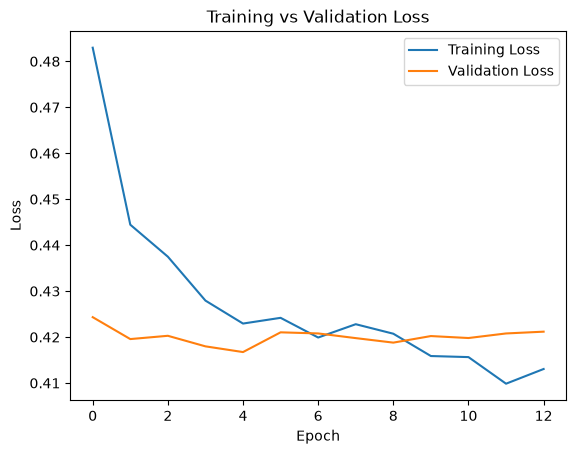

In [35]:
import matplotlib.pyplot as plt

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"] , label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.show()

In [39]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

In [40]:
y_prob = ann_model.predict(X_test_processed).ravel()

y_pred = (y_prob >= 0.5).astype(int)

45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step


In [49]:
from sklearn.metrics import accuracy_score, precision_score , recall_score , f1_score , classification_report , confusion_matrix

ann_accuracy = accuracy_score(y_test_array , y_pred)
print(ann_accuracy)

ann_precision = precision_score(y_test_array , y_pred)
print(ann_precision)

ann_recall = recall_score(y_test_array , y_pred)
print(ann_recall)

ann_f1 = f1_score(y_test_array , y_pred)
print(ann_f1)

0.7977288857345636
0.6498316498316499
0.516042780748663
0.5752608047690015


In [50]:
print(classification_report(y_test_array , y_pred))
print(confusion_matrix(y_test_array , y_pred))

              precision    recall  f1-score   support

         0.0       0.84      0.90      0.87      1035
         1.0       0.65      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409

[[931 104]
 [181 193]]


In [53]:
compare = pd.DataFrame(
    [
    {
        'model': 'SVM',
        'accuracy': 0.7437899219304471,
        'f1_score': 0.6155484558040468,
        'recall': 0.7727272727272727
    },
    {
        "model":"ann",
        "accuracy":ann_accuracy,
        "f1_score":ann_f1,
        "recall":ann_recall
    }
]
)

In [55]:
comparison = compare.sort_values(
    by="recall",
    ascending=False
)

In [56]:
comparison

,model,accuracy,f1_score,recall
0,SVM,0.743790,0.615548,0.772727
1,ann,0.797729,0.575261,0.516043


In [57]:
champion = comparison.iloc[0]

In [59]:
print("Champion:" , champion["model"])

Champion: SVM


In [61]:
import os
ann_model.save(
    "../models/churn_ann.keras"
)